# Import e setup

In [1]:
import os, sys, pickle, ast
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import numpy as np

sys.path.insert(0, os.path.abspath('..'))
import config as cfg

from Sorgente.Preprocessing.preprocesing        import Preprocessore
from Sorgente.Indicizzazione.indice_invertito     import IndiceInvertito
from Sorgente.Recupero.metadati                   import GestoreMetadati
from Sorgente.Recupero.bm25                       import CalcolatoreRanking
from Sorgente.Classificazione.classificatore_nli  import ClassificatoreNLI
from Sorgente.Valutazione.metriche_ir             import MetricheIR
from Sorgente.Valutazione.metriche_nlp            import MetricheNLP
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv()

plt.style.use('seaborn-v0_8-whitegrid')
matplotlib.rcParams['figure.dpi'] = 150

# API Key OpenAI
API_KEY = os.getenv('OPENAI_API_KEY')

print('Import completati.')

Import completati.


In [2]:
# Carica tutte le risorse
print('Caricamento risorse...')

with open('../Notebook/corpus_fever_arricchito.pkl', 'rb') as f:
    corpus_arricchito = pickle.load(f)

indice = IndiceInvertito()
indice.carica('../Dati/Elaborati/indice_fever.pkl')

preprocessore    = Preprocessore()
metadati         = GestoreMetadati(corpus_arricchito)
ranking          = CalcolatoreRanking(indice, preprocessore, metadati)
classificatore   = ClassificatoreNLI(API_KEY)
metriche_ir      = MetricheIR()
metriche_nlp     = MetricheNLP()

print(f'Corpus:  {len(corpus_arricchito):,} documenti')
print(f'Indice:  {indice.numero_termini:,} termini')
print(f'Risorse caricate.')

Caricamento risorse...
Corpus:  14,364 documenti
Indice:  71,837 termini
Risorse caricate.


In [3]:
# Carica il paper_dev come test set finale
# ATTENZIONE: questo split va usato solo qui, non durante lo sviluppo
from datasets import load_dataset

print('Caricamento paper_dev (test set finale)...')
dataset_fever = load_dataset('fever', 'v1.0')
df_test_raw   = pd.DataFrame(dataset_fever['paper_dev'])

# Raggruppa per claim (il dataset è appiattito)
df_test = df_test_raw.groupby('id').agg(
    testo_claim     = ('claim',               'first'),
    label           = ('label',               'first'),
    url_documenti   = ('evidence_wiki_url',    lambda x: list(x.dropna().unique())),
    sentence_ids    = ('evidence_sentence_id', list)
).reset_index()

print(f'Claim totali paper_dev: {len(df_test):,}')
print(df_test['label'].value_counts().to_string())

# Per contenere i costi API usiamo un campione bilanciato
# Per la valutazione finale reale rimuovi questo limite
N_PER_CLASSE = 50   # 50 per classe = 150 claim totali
campioni = []
for label in cfg.TUTTE_LE_LABEL:
    subset = df_test[df_test['label'] == label]
    campioni.append(subset.sample(n=min(N_PER_CLASSE, len(subset)), random_state=42))
df_valutazione = pd.concat(campioni).reset_index(drop=True)

print(f'\nCampione valutazione: {len(df_valutazione)} claim ({N_PER_CLASSE} per classe)')

C:\Users\ANGELICA\Desktop\ANGELICA\UNICAL\MAGISTRALE\II ANNO\PRIMO SEMESTRE\INFORMATION RETRIVIAL AND NLP\PROGETTO\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Caricamento paper_dev (test set finale)...


C:\Users\ANGELICA\Desktop\ANGELICA\UNICAL\MAGISTRALE\II ANNO\PRIMO SEMESTRE\INFORMATION RETRIVIAL AND NLP\PROGETTO\.venv\Lib\site-packages\datasets\load.py:1486: FutureWarning: The repository for fever contains custom code which must be executed to correctly load the dataset. You can inspect the repository content at https://hf.co/datasets/fever
You can avoid this message in future by passing the argument `trust_remote_code=True`.
Passing `trust_remote_code=True` will be mandatory to load this dataset from the next major release of `datasets`.
  warnings.warn(


Claim totali paper_dev: 9,999
label
NOT ENOUGH INFO    3333
REFUTES            3333
SUPPORTS           3333

Campione valutazione: 150 claim (50 per classe)


# Valutazione IR - Qualità del recupero BM25

In [4]:
# Valuta il recupero BM25 su tutte le claim con documenti rilevanti
# Le claim NOT ENOUGH INFO vengono escluse (nessun documento da trovare)

print('Valutazione IR in corso...')
risultati_ir = []

df_ir = df_valutazione[df_valutazione['label'] != cfg.LABEL_INSUFFICIENTE]

for _, riga in df_ir.iterrows():
    doc_rilevanti = set(u for u in riga['url_documenti'] if u)
    if not doc_rilevanti:
        continue

    risultati_bm25 = ranking.recupera_top_k(
        riga['testo_claim'], k=10
    )
    id_recuperati = [r['id_doc'] for r in risultati_bm25]

    risultati_ir.append({
        'recuperati': id_recuperati,
        'rilevanti':  doc_rilevanti
    })

metriche_ir_finali = metriche_ir.valuta_sistema(
    risultati_ir, k_valori=cfg.K_VALORI_VALUTAZIONE
)

print(f'\nRISULTATI IR (su {len(risultati_ir)} claim con documenti rilevanti)')
print('=' * 50)
print(f"  MAP:   {metriche_ir_finali['MAP']:.4f}")
print()
for k in cfg.K_VALORI_VALUTAZIONE:
    print(f"  P@{k:<3}  {metriche_ir_finali[f'P@{k}']:.4f}  "
          f"R@{k:<3}  {metriche_ir_finali[f'R@{k}']:.4f}  "
          f"F1@{k:<3} {metriche_ir_finali[f'F1@{k}']:.4f}")

Valutazione IR in corso...

RISULTATI IR (su 100 claim con documenti rilevanti)
  MAP:   0.7996

  P@1    0.7400  R@1    0.7000  F1@1   0.7113
  P@3    0.3133  R@3    0.8675  F1@3   0.4536
  P@5    0.1940  R@5    0.8975  F1@5   0.3152
  P@10   0.1020  R@10   0.9300  F1@10  0.1821


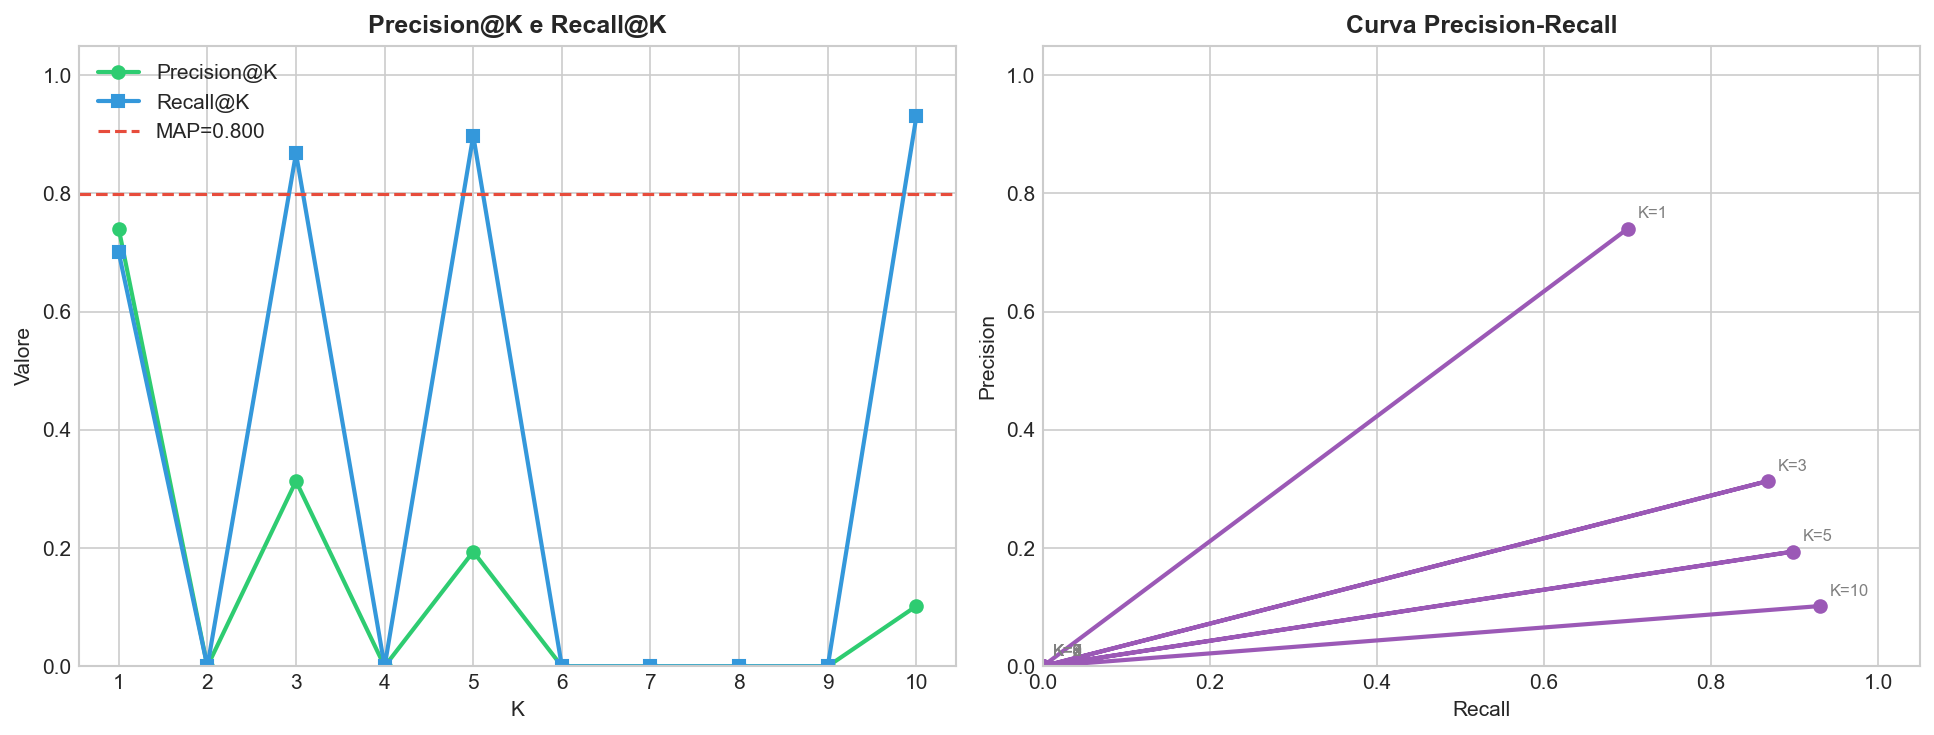

Salvata: curva_precision_recall.png


In [5]:
# Curva Precision-Recall
k_range = range(1, 11)
precision_vals = [metriche_ir_finali.get(f'P@{k}', 0) for k in k_range]
recall_vals    = [metriche_ir_finali.get(f'R@{k}', 0) for k in k_range]

fig, assi = plt.subplots(1, 2, figsize=(13, 5))

# P@K e R@K al variare di K
assi[0].plot(list(k_range), precision_vals, 'o-', color='#2ecc71',
             linewidth=2, markersize=6, label='Precision@K')
assi[0].plot(list(k_range), recall_vals, 's-', color='#3498db',
             linewidth=2, markersize=6, label='Recall@K')
assi[0].axhline(metriche_ir_finali['MAP'], color='#e74c3c',
                linestyle='--', linewidth=1.5, label=f"MAP={metriche_ir_finali['MAP']:.3f}")
assi[0].set_xlabel('K')
assi[0].set_ylabel('Valore')
assi[0].set_title('Precision@K e Recall@K', fontsize=12, fontweight='bold')
assi[0].legend()
assi[0].set_ylim(0, 1.05)
assi[0].set_xticks(list(k_range))

# Curva Precision-Recall
assi[1].plot(recall_vals, precision_vals, 'o-', color='#9b59b6',
             linewidth=2, markersize=6)
for k, (r, p) in zip(k_range, zip(recall_vals, precision_vals)):
    assi[1].annotate(f'K={k}', (r, p), textcoords='offset points',
                     xytext=(5, 5), fontsize=8, color='gray')
assi[1].set_xlabel('Recall')
assi[1].set_ylabel('Precision')
assi[1].set_title('Curva Precision-Recall', fontsize=12, fontweight='bold')
assi[1].set_xlim(0, 1.05)
assi[1].set_ylim(0, 1.05)

plt.tight_layout()
plt.savefig('curva_precision_recall.png', bbox_inches='tight')
plt.show()
print('Salvata: curva_precision_recall.png')

# Valutazione NLI - Qualità della classificazione

In [6]:
# Classificazione NLI su tutto il campione di valutazione
print(f'Classificazione NLI su {len(df_valutazione)} claim...')
print('(ogni claim usa k=5 documenti → chiamate API OpenAI)')
print()

label_vere     = []
label_predette = []

for i, (_, riga) in enumerate(df_valutazione.iterrows()):
    # Mappa sentence_ids per le frasi rilevanti
    sentence_ids_map = {}
    for url, sid in zip(riga['url_documenti'], riga['sentence_ids']):
        if url:
            sentence_ids_map.setdefault(url, []).append(sid)

    # Recupero e classificazione
    risultati_bm25 = ranking.recupera_top_k(
        riga['testo_claim'], k=cfg.DOCUMENTI_DA_RECUPERARE
    )
    if risultati_bm25:
        risultato = classificatore.verifica(
            claim             = riga['testo_claim'],
            risultati_bm25    = risultati_bm25,
            corpus_arricchito = corpus_arricchito,
            sentence_ids_map  = sentence_ids_map or None
        )
        label_predetta = risultato['verdetto']
    else:
        label_predetta = cfg.LABEL_INSUFFICIENTE

    label_vere.append(riga['label'])
    label_predette.append(label_predetta)

    if (i + 1) % 10 == 0:
        print(f'  {i+1}/{len(df_valutazione)} claim elaborate...')

print('\nClassificazione completata.')

Classificazione NLI su 150 claim...
(ogni claim usa k=5 documenti → chiamate API OpenAI)

  10/150 claim elaborate...
  20/150 claim elaborate...
  30/150 claim elaborate...
  40/150 claim elaborate...
  50/150 claim elaborate...
  60/150 claim elaborate...
  70/150 claim elaborate...
  80/150 claim elaborate...
  90/150 claim elaborate...
  100/150 claim elaborate...
  110/150 claim elaborate...
  120/150 claim elaborate...
  130/150 claim elaborate...
  140/150 claim elaborate...
  150/150 claim elaborate...

Classificazione completata.


In [7]:
# Calcola e stampa le metriche NLP
metriche_nlp_finali = metriche_nlp.valuta_sistema(label_vere, label_predette)
metriche_nlp.stampa_report(label_vere, label_predette)

REPORT VALUTAZIONE NLI
Classe                  Precision   Recall       F1   Support
------------------------------------------------------------
  SUPPORTS                 0.8333   0.1000   0.1786        50
  REFUTES                  0.5833   0.5600   0.5714        50
  NOT ENOUGH INFO          0.3438   0.6600   0.4521        50
------------------------------------------------------------
  Accuracy                 0.4400
  F1 Macro                 0.4007
  Kappa di Cohen           0.1600
  → Kappa: accordo scarso


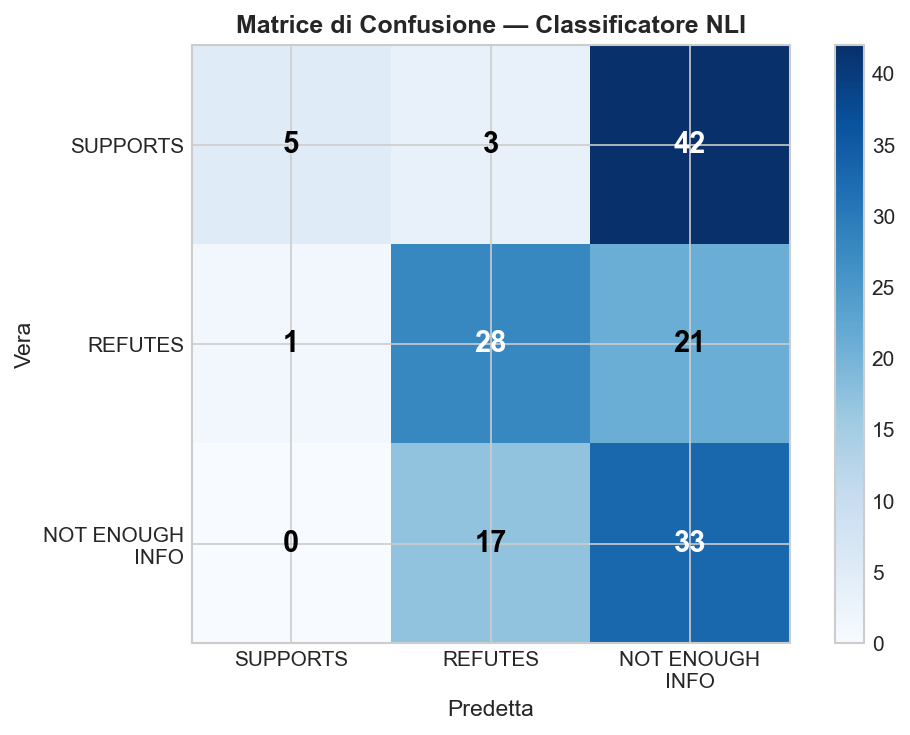

Salvata: matrice_confusione_finale.png


In [8]:
# Matrice di confusione
from Sorgente.Valutazione.metriche_nlp import LABEL_FEVER

cm_dict  = metriche_nlp.matrice_confusione(label_vere, label_predette)
classi   = LABEL_FEVER
cm_array = np.array([[cm_dict[(v, p)] for p in classi] for v in classi])

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(cm_array, cmap='Blues')

etichette = ['SUPPORTS', 'REFUTES', 'NOT ENOUGH\nINFO']
ax.set_xticks(range(len(classi)))
ax.set_yticks(range(len(classi)))
ax.set_xticklabels(etichette)
ax.set_yticklabels(etichette)
ax.set_xlabel('Predetta', fontsize=11)
ax.set_ylabel('Vera', fontsize=11)
ax.set_title('Matrice di Confusione — Classificatore NLI',
             fontsize=12, fontweight='bold')

for i in range(len(classi)):
    for j in range(len(classi)):
        colore = 'white' if cm_array[i, j] > cm_array.max() / 2 else 'black'
        ax.text(j, i, str(cm_array[i, j]),
                ha='center', va='center', color=colore,
                fontsize=14, fontweight='bold')

plt.colorbar(im)
plt.tight_layout()
plt.savefig('matrice_confusione_finale.png', bbox_inches='tight')
plt.show()
print('Salvata: matrice_confusione_finale.png')

# Confronto BM25 base vs BM25 esteso

In [9]:
# Confronta P@K e R@K con e senza metadati (authority + freshness)
# Per isolare l'impatto dei metadati, ricalcola il ranking senza di essi
import math

def recupera_bm25_puro(query, indice, preprocessore, k=10):
    """BM25 senza metadati — per confronto."""
    token = preprocessore.elabora(query)
    if not token:
        return []
    avgdl    = indice.lunghezza_media_documenti()
    punteggi = {}
    for t in token:
        N   = indice.numero_documenti
        df  = indice.documenti_con_termine(t)
        if df == 0:
            continue
        idf = math.log((N - df + 0.5) / (df + 0.5) + 1)
        for id_doc, tf in indice.cerca(t).items():
            lung = indice.lunghezza_documento(id_doc)
            norm = 1 - cfg.B + cfg.B * (lung / avgdl)
            tf_b = (tf * (cfg.K1 + 1)) / (tf + cfg.K1 * norm)
            punteggi[id_doc] = punteggi.get(id_doc, 0.0) + idf * tf_b
    return [id_doc for id_doc, _ in sorted(punteggi.items(), key=lambda x: -x[1])[:k]]

risultati_puro   = []
risultati_esteso = []

for _, riga in df_ir.iterrows():
    rilevanti = set(u for u in riga['url_documenti'] if u)
    if not rilevanti:
        continue
    recuperati_puro   = recupera_bm25_puro(riga['testo_claim'], indice, preprocessore)
    recuperati_esteso = [r['id_doc'] for r in ranking.recupera_top_k(riga['testo_claim'], k=10)]
    risultati_puro.append({'recuperati': recuperati_puro,   'rilevanti': rilevanti})
    risultati_esteso.append({'recuperati': recuperati_esteso, 'rilevanti': rilevanti})

metriche_puro   = metriche_ir.valuta_sistema(risultati_puro)
metriche_esteso = metriche_ir.valuta_sistema(risultati_esteso)

print('CONFRONTO BM25 BASE vs BM25 ESTESO')
print('=' * 55)
print(f"{'Metrica':<10} {'BM25 base':>12} {'BM25 esteso':>13} {'Δ':>8}")
print('-' * 45)
metriche_confronto = ['MAP'] + [f'P@{k}' for k in [1, 5, 10]]
for m in metriche_confronto:
    v_base   = metriche_puro.get(m, 0)
    v_esteso = metriche_esteso.get(m, 0)
    delta    = v_esteso - v_base
    segno    = '+' if delta >= 0 else ''
    print(f"  {m:<10} {v_base:>10.4f}   {v_esteso:>10.4f}   {segno}{delta:.4f}")

CONFRONTO BM25 BASE vs BM25 ESTESO
Metrica       BM25 base   BM25 esteso        Δ
---------------------------------------------
  MAP            0.7996       0.7996   +0.0000
  P@1            0.7400       0.7400   +0.0000
  P@5            0.1940       0.1940   +0.0000
  P@10           0.1020       0.1020   +0.0000


# Riepilogo finale

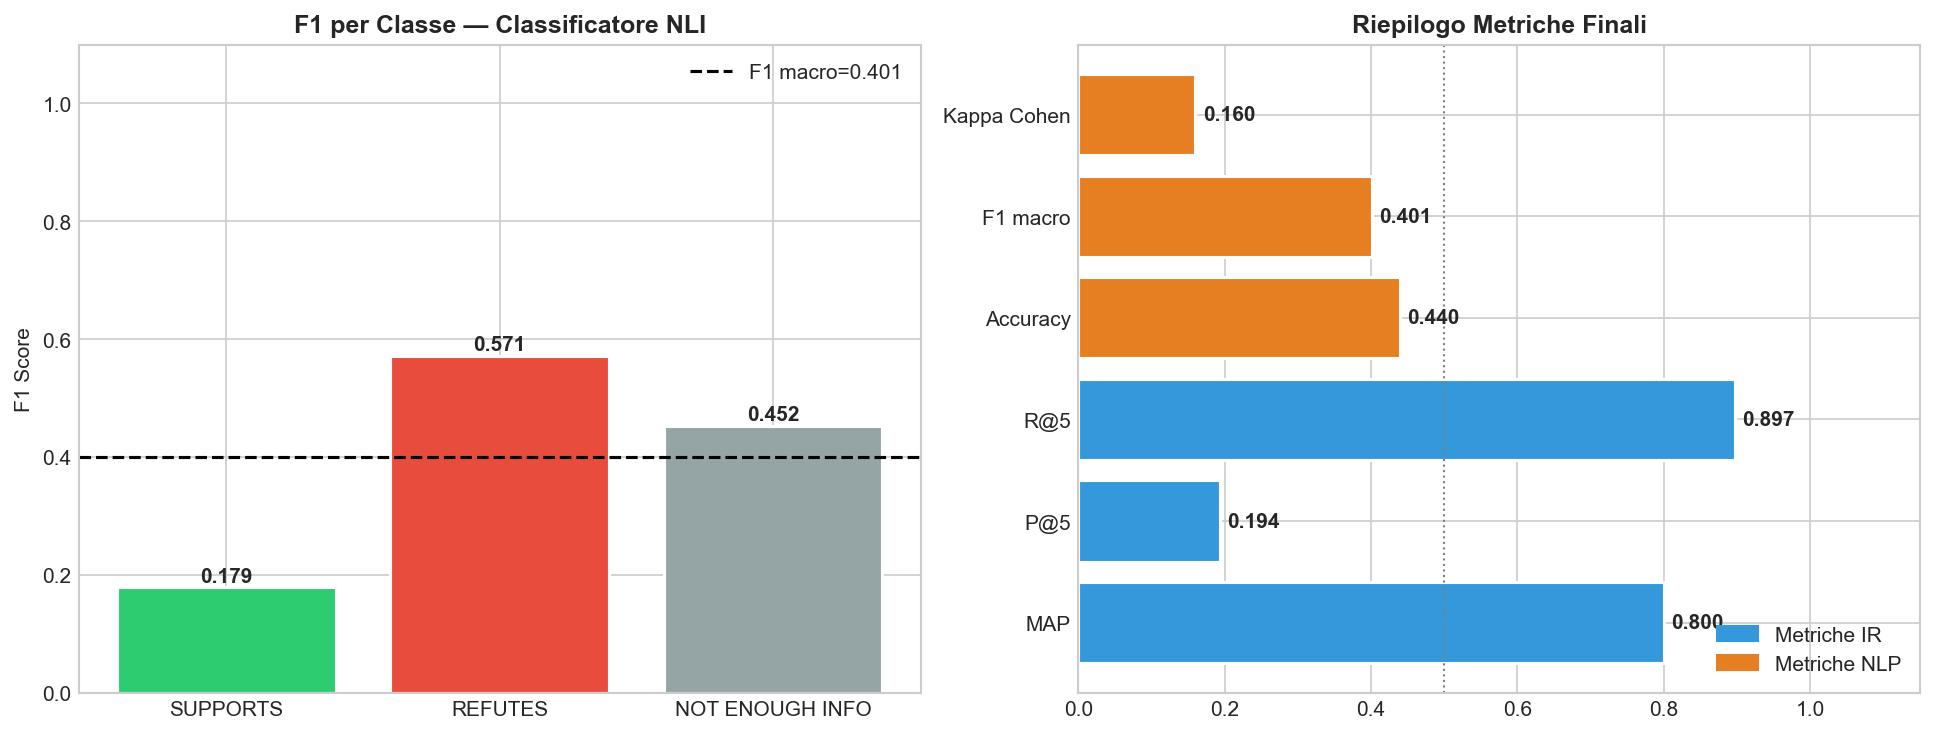

Salvata: riepilogo_metriche_finali.png


In [10]:
# Grafico riassuntivo: F1 per classe
classi_brevi = ['SUPPORTS', 'REFUTES', 'NOT ENOUGH INFO']
f1_per_classe = [
    metriche_nlp_finali['per_classe'][c]['f1']
    for c in cfg.TUTTE_LE_LABEL
]

fig, assi = plt.subplots(1, 2, figsize=(13, 5))

# F1 per classe
colori = ['#2ecc71', '#e74c3c', '#95a5a6']
barre  = assi[0].bar(classi_brevi, f1_per_classe, color=colori,
                     edgecolor='white', linewidth=1.5)
assi[0].axhline(metriche_nlp_finali['f1_macro'], color='black',
                linestyle='--', linewidth=1.5,
                label=f"F1 macro={metriche_nlp_finali['f1_macro']:.3f}")
for barra, val in zip(barre, f1_per_classe):
    assi[0].text(barra.get_x() + barra.get_width()/2, val + 0.01,
                 f'{val:.3f}', ha='center', fontweight='bold')
assi[0].set_ylim(0, 1.1)
assi[0].set_title('F1 per Classe — Classificatore NLI',
                  fontsize=12, fontweight='bold')
assi[0].set_ylabel('F1 Score')
assi[0].legend()

# Riepilogo metriche chiave
metriche_chiave = {
    'MAP':           metriche_ir_finali['MAP'],
    'P@5':           metriche_ir_finali.get('P@5', 0),
    'R@5':           metriche_ir_finali.get('R@5', 0),
    'Accuracy':      metriche_nlp_finali['accuracy'],
    'F1 macro':      metriche_nlp_finali['f1_macro'],
    'Kappa Cohen':   metriche_nlp_finali['kappa_cohen']
}
nomi   = list(metriche_chiave.keys())
valori = list(metriche_chiave.values())
colori_riepilogo = ['#3498db']*3 + ['#e67e22']*3

barre2 = assi[1].barh(nomi, valori, color=colori_riepilogo,
                      edgecolor='white', linewidth=1.5)
for barra, val in zip(barre2, valori):
    assi[1].text(val + 0.01, barra.get_y() + barra.get_height()/2,
                 f'{val:.3f}', va='center', fontweight='bold')
assi[1].set_xlim(0, 1.15)
assi[1].set_title('Riepilogo Metriche Finali',
                  fontsize=12, fontweight='bold')
assi[1].axvline(0.5, color='gray', linestyle=':', linewidth=1)

# Legenda colori
from matplotlib.patches import Patch
legenda = [Patch(color='#3498db', label='Metriche IR'),
           Patch(color='#e67e22', label='Metriche NLP')]
assi[1].legend(handles=legenda, loc='lower right')

plt.tight_layout()
plt.savefig('riepilogo_metriche_finali.png', bbox_inches='tight')
plt.show()
print('Salvata: riepilogo_metriche_finali.png')

In [11]:
# Stampa riepilogo completo per la relazione
kappa = metriche_nlp_finali['kappa_cohen']
if kappa > 0.80:
    interp_kappa = 'accordo quasi perfetto'
elif kappa > 0.60:
    interp_kappa = 'accordo sostanziale'
elif kappa > 0.40:
    interp_kappa = 'accordo moderato'
elif kappa > 0.20:
    interp_kappa = 'accordo discreto'
else:
    interp_kappa = 'accordo scarso'

print(f"""
╔══════════════════════════════════════════════════════════════════╗
║              RISULTATI FINALI — SISTEMA FACT-CHECKING           ║
╚══════════════════════════════════════════════════════════════════╝

CONFIGURAZIONE
  Dataset:         FEVER v1.0 — paper_dev ({len(df_valutazione)} claim)
  BM25:            k1={cfg.K1}, b={cfg.B}
  Pesi metadati:   α={cfg.PESO_AUTHORITY} (authority), β={cfg.PESO_FRESHNESS} (freshness)
  Documenti top-K: {cfg.DOCUMENTI_DA_RECUPERARE}
  Espansione query: {'attiva' if cfg.ESPANSIONE_ATTIVA else 'disabilitata'}
  Modello LLM:     {cfg.MODELLO_LLM}

METRICHE IR (BM25 esteso, su {len(risultati_ir)} claim con evidenze)
  MAP:    {metriche_ir_finali['MAP']:.4f}
  P@1:    {metriche_ir_finali.get('P@1', 0):.4f}
  P@5:    {metriche_ir_finali.get('P@5', 0):.4f}
  R@5:    {metriche_ir_finali.get('R@5', 0):.4f}
  P@10:   {metriche_ir_finali.get('P@10', 0):.4f}
  R@10:   {metriche_ir_finali.get('R@10', 0):.4f}

METRICHE NLP (su {len(label_vere)} claim)
  Accuracy:        {metriche_nlp_finali['accuracy']:.4f}
  F1 macro:        {metriche_nlp_finali['f1_macro']:.4f}
  Kappa di Cohen:  {metriche_nlp_finali['kappa_cohen']:.4f}  ({interp_kappa})

  Per classe:
    SUPPORTS        P={metriche_nlp_finali['per_classe']['SUPPORTS']['precision']:.3f}  R={metriche_nlp_finali['per_classe']['SUPPORTS']['recall']:.3f}  F1={metriche_nlp_finali['per_classe']['SUPPORTS']['f1']:.3f}
    REFUTES         P={metriche_nlp_finali['per_classe']['REFUTES']['precision']:.3f}  R={metriche_nlp_finali['per_classe']['REFUTES']['recall']:.3f}  F1={metriche_nlp_finali['per_classe']['REFUTES']['f1']:.3f}
    NOT ENOUGH INFO P={metriche_nlp_finali['per_classe']['NOT ENOUGH INFO']['precision']:.3f}  R={metriche_nlp_finali['per_classe']['NOT ENOUGH INFO']['recall']:.3f}  F1={metriche_nlp_finali['per_classe']['NOT ENOUGH INFO']['f1']:.3f}

FILE PRODOTTI
  curva_precision_recall.png
  matrice_confusione_finale.png
  riepilogo_metriche_finali.png
""")


╔══════════════════════════════════════════════════════════════════╗
║              RISULTATI FINALI — SISTEMA FACT-CHECKING           ║
╚══════════════════════════════════════════════════════════════════╝

CONFIGURAZIONE
  Dataset:         FEVER v1.0 — paper_dev (150 claim)
  BM25:            k1=1.5, b=0.75
  Pesi metadati:   α=0.3 (authority), β=0.2 (freshness)
  Documenti top-K: 10
  Espansione query: disabilitata
  Modello LLM:     gpt-4o-mini

METRICHE IR (BM25 esteso, su 100 claim con evidenze)
  MAP:    0.7996
  P@1:    0.7400
  P@5:    0.1940
  R@5:    0.8975
  P@10:   0.1020
  R@10:   0.9300

METRICHE NLP (su 150 claim)
  Accuracy:        0.4400
  F1 macro:        0.4007
  Kappa di Cohen:  0.1600  (accordo scarso)

  Per classe:
    SUPPORTS        P=0.833  R=0.100  F1=0.179
    REFUTES         P=0.583  R=0.560  F1=0.571
    NOT ENOUGH INFO P=0.344  R=0.660  F1=0.452

FILE PRODOTTI
  curva_precision_recall.png
  matrice_confusione_finale.png
  riepilogo_metriche_finali.png

